# TF++ perception analysis: predicted boxes vs CARLA ground truth (schema v2, 220 Bench2Drive routes)

This notebook evaluates **TF++'s perception outputs only**: how well its predicted bounding boxes match the actors actually around the car. It does not look at planning or control. Data: the 220 Bench2Drive routes run with **schema-v2 logging** (`results/bench2drive_v2`).

**What TF++ logs**

- **The only logged perception output is `pred_boxes`.** These are taken after non-maximum suppression across the ensemble and the score ≥ 0.3 cut-off.
- **Box format:** `[x, y, extent_x, extent_y, yaw, speed, brake, class, score]` in the ego frame (x forward, y right, extents are half-lengths in m).
- **Classes:** 0 car, 1 walker, 2 traffic light, 3 stop sign, 4 emergency vehicle.
- **Not logged:** TF++'s other perception heads (BEV semantics, depth, semantic segmentation), so they cannot be evaluated here.

**Ground truth** (`gt_actors`) is every vehicle, walker and static prop within 60 m of the ego, in the same frame. It has no traffic lights or stop signs, so those box classes are counted but not scored.

**Evaluation protocol**

- **Scope.** Only ground-truth actors inside TF++'s box range (|x| ≤ 32 m and |y| ≤ 32 m) are scored, at every 20 Hz step.
- **Matching** (nuScenes style). Boxes are taken in descending score order. Each one claims the nearest unmatched ground-truth actor of a compatible class whose centre is within *d* metres, for *d* = 0.5, 1, 2 and 4 m. **2 m is the primary threshold.**
  - Compatible classes: car or emergency box ↔ car, large vehicle or emergency vehicle; walker box ↔ pedestrian; any of car, walker or emergency box ↔ two-wheeler.
- **Metrics.** Recall, precision, AP (over the logged boxes, which all have score ≥ 0.3), position, size and heading errors, and BEV IoU (on every 10th step).
- **Track stability.** Dropouts and how long it takes for an actor to be detected after it comes into range.
- **Breakdowns** by distance, occlusion, actor type and speed, town, weather and scenario.
- **Occlusion** is a 2D line-of-sight estimate: the share of an actor's angular width, as seen from the ego, that is hidden behind closer vehicles.
- **Confidence intervals** are 95% bootstraps that resample **routes**, because steps within a route are highly correlated.

**Run**

```bash
uv run --no-project --with numpy --with matplotlib --with jupyter \
  jupyter nbconvert --to notebook --execute --inplace notebooks/perception_analysis.ipynb
```

The code is in [`src/perception_analysis.py`](../src/perception_analysis.py). Outputs (CSV tables, PNG figures and a cache) go to `results/bench2drive_v2/perception/`.

## 0. Setup

In [1]:
import sys, csv, json, math, time, collections
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))
import perception_analysis as pa

RESULTS = REPO / "results" / "bench2drive_v2"
OUT = RESULTS / "perception"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
CAT_COL = ["#2471a3", "#7d3c98", "#b9770e", "#c0392b", "#17a589"]

def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

def show_table(rows, cols=None, fmt=None, headers=None):
    cols = cols or list(rows[0])
    fmt = fmt or {}
    lines = ["| " + " | ".join(headers or cols) + " |", "|" + "---|" * len(cols)]
    for r in rows:
        lines.append("| " + " | ".join(fmt[c](r[c]) if c in fmt and r.get(c, "") != "" else
                                       (f"{r[c]:.3g}" if isinstance(r.get(c), float) else str(r.get(c, ""))) for c in cols) + " |")
    display(Markdown("\n".join(lines)))

def write_csv(name, rows):
    with open(OUT / f"{name}.csv", "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(rows[0]), extrasaction="ignore")
        w.writeheader(); w.writerows(rows)

pct = lambda v: f"{100 * v:.1f}%"
def pci(t):
    return f"{100 * t[0]:.1f}% [{100 * t[1]:.1f}, {100 * t[2]:.1f}]"

In [2]:
t0 = time.time()
C = pa.build_cache(RESULTS, REPO / "carla_garage/leaderboard/data/bench2drive220.xml", OUT / "cache.pkl")
routes, outcomes, data = C["routes"], C["outcomes"], C["data"]
gt, box, tl, st = (pa.stack(data, k) for k in ("gt", "box", "tl", "steps"))
gt["dist"] = np.hypot(gt["x"], gt["y"])
gt["bearing"] = np.degrees(np.arctan2(gt["y"], gt["x"]))
gt["moving"] = gt["speed"] >= 0.5
box["dist"] = np.hypot(box["x"], box["y"])
P = f"det_{pa.THRESHOLDS[pa.PRIMARY]}"
PB = f"tp_{pa.THRESHOLDS[pa.PRIMARY]}"
minutes = len(st["ego_speed"]) * pa.DT / 60
print(f"loaded in {time.time() - t0:.0f} s: {len(data)} routes, {len(st['ego_speed']):,} steps ({minutes:.0f} min of driving)")
print(f"ground-truth actor-steps in box range: {len(gt['step']):,}   predicted car/walker/emergency boxes: {len(box['step']):,}")

loaded in 1 s: 220 routes, 176,329 steps (147 min of driving)
ground-truth actor-steps in box range: 1,305,262   predicted car/walker/emergency boxes: 1,144,735


## 1. Inventory: what TF++ outputs

In [3]:
rows = []
for c, name in pa.BOX_CLASSES.items():
    n = int((box["cls"] == c).sum()) if c in (0, 1, 4) else int((tl["cls"] == c).sum())
    s = box["score"][box["cls"] == c] if c in (0, 1, 4) else tl["score"][tl["cls"] == c]
    rows.append({"class": f"{c} {name}", "boxes": n, "box-instances per minute": n / minutes,
                 "median score": float(np.median(s)) if n else float("nan"),
                 "evaluated against GT": "yes" if c in (0, 1, 4) else "no (no GT for this class)"})
show_table(rows, fmt={"box-instances per minute": lambda v: f"{v:.1f}", "median score": lambda v: f"{v:.2f}"})
write_csv("box_inventory", rows)
print(f"boxes per step: mean {st['n_box'].mean():.1f}, GT actors in range per step: mean {st['n_gt'].mean():.1f}")
print(f"box 'speed' field: non-zero in {np.mean(box['speed_field'] != 0):.4%} of boxes (max {box['speed_field'].max():.3f})")
print(f"box 'brake' field: non-zero in {np.mean(box['brake_field'] != 0):.4%} of boxes")
print("=> TF++'s box speed and brake outputs are constant 0 in this checkpoint; only position, size, heading, class and score carry information.")

| class | boxes | box-instances per minute | median score | evaluated against GT |
|---|---|---|---|---|
| 0 car | 1132662 | 7708.3 | 0.82 | yes |
| 1 walker | 1900 | 12.9 | 0.64 | yes |
| 2 traffic light | 27731 | 188.7 | 0.81 | no (no GT for this class) |
| 3 stop sign | 2268 | 15.4 | 0.70 | no (no GT for this class) |
| 4 emergency vehicle | 10173 | 69.2 | 0.64 | yes |

boxes per step: mean 6.5, GT actors in range per step: mean 7.4
box 'speed' field: non-zero in 0.0000% of boxes (max 0.000)
box 'brake' field: non-zero in 0.0000% of boxes
=> TF++'s box speed and brake outputs are constant 0 in this checkpoint; only position, size, heading, class and score carry information.


## 2. Ground-truth caveat: actors parked below the map

Bench2Drive scenarios spawn some actors 50–500 m **below the road** and lift them into place when the scenario triggers. Examples:

- `pedestrian_crossing.py` and `object_crash_vehicle.py`: `spawn_transform.location.z -= 50`;
- `cut_in_with_static_vehicle.py`: `z=-500`;
- `construction_crash_vehicle.py`: `z -= 200`.

The logged ground truth has no height (z), so while such an actor is hidden it looks like a stationary actor, which TF++ cannot possibly see. Two-level roads (overpasses) cause the same problem.

The cell below shows how much this matters. Any ground-truth actor whose box **overlaps the ego's own footprint** without a collision must be underground or on another level, because a real actor in that position would be touching the car.

**Moving actors** (≥ 0.5 m/s) are certainly above ground (overpasses aside). **Headline recall is therefore reported on moving actors**, and all-actor recall is given as a lower bound.

In [4]:
ego_x, ego_y = 2.45, 1.06
inside = (np.abs(gt["x"]) < ego_x + gt["ext_x"] * 0.5) & (np.abs(gt["y"]) < ego_y + gt["ext_y"] * 0.5)
rows = []
for name, m in (("moving (>= 0.5 m/s)", gt["moving"]), ("stationary", ~gt["moving"])):
    rows.append({"actors": name, "actor-steps": int(m.sum()), "share": float(m.mean()),
                 "overlapping the ego footprint (impossible above ground)": int((m & inside).sum()),
                 "recall @2 m": float(gt[P][m].mean())})
show_table(rows, fmt={"share": pct, "recall @2 m": pct})
hid = collections.Counter((pa.GT_CATS[c]) for c in gt["cat"][inside & ~gt["moving"]])
print("stationary actor-steps inside the ego footprint, by category:", dict(hid))
print("These are certainly hidden; more hidden actors sit at other positions and cannot be identified without z.")

| actors | actor-steps | share | overlapping the ego footprint (impossible above ground) | recall @2 m |
|---|---|---|---|---|
| moving (>= 0.5 m/s) | 531582 | 40.7% | 150 | 92.3% |
| stationary | 773680 | 59.3% | 1891 | 77.9% |

stationary actor-steps inside the ego footprint, by category: {'pedestrian': 973, 'car': 918}
These are certainly hidden; more hidden actors sit at other positions and cannot be identified without z.


## 3. Headline detection quality

In [5]:
rows = []
for d in pa.THRESHOLDS:
    for name, m in (("moving actors", gt["moving"]), ("all actors (lower bound)", np.ones(len(gt["step"]), bool))):
        r = pa.ratio_ci(gt[f"det_{d}"][m], np.ones(m.sum()), gt["route"][m])
        rows.append({"match threshold": f"{d} m", "subset": name, "recall [95% CI]": pci(r)})
    p = pa.ratio_ci(box[f"tp_{d}"], np.ones(len(box["step"])), box["route"])
    rows.append({"match threshold": f"{d} m", "subset": "all predicted boxes", "recall [95% CI]": "", "precision [95% CI]": pci(p)})
show_table(rows, ["match threshold", "subset", "recall [95% CI]", "precision [95% CI]"])
write_csv("headline_recall_precision", rows)

| match threshold | subset | recall [95% CI] | precision [95% CI] |
|---|---|---|---|
| 0.5 m | moving actors | 79.9% [75.5, 84.5] |  |
| 0.5 m | all actors (lower bound) | 70.3% [64.6, 76.1] |  |
| 0.5 m | all predicted boxes |  | 80.2% [73.4, 86.4] |
| 1.0 m | moving actors | 90.5% [89.3, 91.9] |  |
| 1.0 m | all actors (lower bound) | 81.3% [76.8, 85.9] |  |
| 1.0 m | all predicted boxes |  | 92.7% [88.2, 96.1] |
| 2.0 m | moving actors | 92.3% [91.1, 93.4] |  |
| 2.0 m | all actors (lower bound) | 83.8% [79.7, 87.9] |  |
| 2.0 m | all predicted boxes |  | 95.5% [91.2, 98.1] |
| 4.0 m | moving actors | 92.5% [91.2, 93.6] |  |
| 4.0 m | all actors (lower bound) | 84.3% [80.4, 88.2] |  |
| 4.0 m | all predicted boxes |  | 96.1% [91.9, 98.6] |

| class | AP@0.5 m | AP@1.0 m | AP@2.0 m | AP@4.0 m |
|---|---|---|---|---|
| vehicles (car, large, two-wheeler, emergency) | 0.659 | 0.805 | 0.833 | 0.838 |
| pedestrians | 0.059 | 0.159 | 0.183 | 0.185 |

AP is computed over all ground-truth actors in range (hidden ones included) and over the logged boxes only (score >= 0.3),
so it is a lower bound; mean over thresholds (nuScenes-style mAP) per class: {'vehicles (car, large, two-wheeler, emergency)': 0.784, 'pedestrians': 0.146}


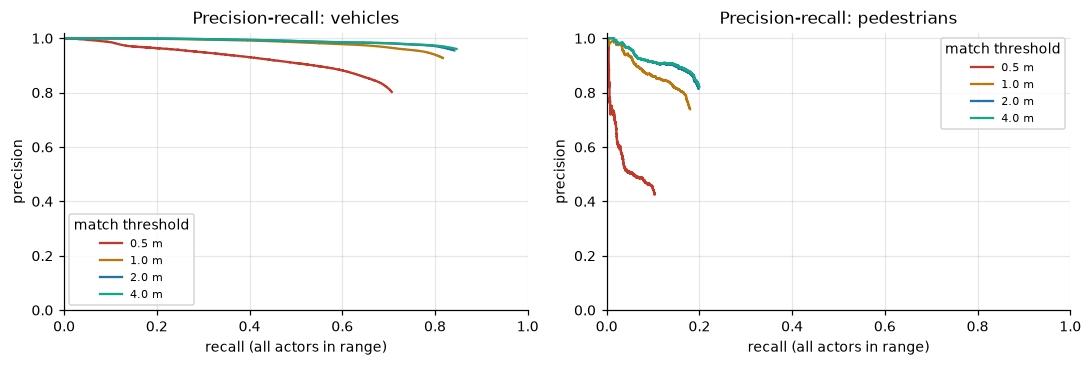

In [6]:
rows, curves = [], {}
for cname, gmask, bmask in (("vehicles (car, large, two-wheeler, emergency)", gt["cat"] != 4, box["cls"] != 1),
                            ("pedestrians", gt["cat"] == 4, box["cls"] == 1)):
    r = {"class": cname}
    for d in pa.THRESHOLDS:
        ap, rec, prec = pa.average_precision(box["score"][bmask], box[f"tp_{d}"][bmask], int(gmask.sum()))
        r[f"AP@{d} m"] = ap
        curves[(cname, d)] = (rec, prec)
    rows.append(r)
show_table(rows, fmt={k: lambda v: f"{v:.3f}" for k in rows[0] if k.startswith("AP")})
print("AP is computed over all ground-truth actors in range (hidden ones included) and over the logged boxes only (score >= 0.3),")
print("so it is a lower bound; mean over thresholds (nuScenes-style mAP) per class:",
      {r["class"]: round(float(np.mean([r[f'AP@{d} m'] for d in pa.THRESHOLDS])), 3) for r in rows})
write_csv("average_precision", rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, cname in zip(axes, [r["class"] for r in rows]):
    for d, c in zip(pa.THRESHOLDS, ["#c0392b", "#b9770e", "#2471a3", "#17a589"]):
        rec, prec = curves[(cname, d)]
        ax.plot(rec, prec, color=c, label=f"{d} m")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_xlabel("recall (all actors in range)"); ax.set_ylabel("precision")
    ax.set_title(f"Precision-recall: {cname.split(' (')[0]}"); ax.legend(title="match threshold", fontsize=7)
plt.tight_layout(); savefig("01_precision_recall"); plt.show()

In [7]:
# class confusion for matched pairs (primary threshold) and miss rate per GT category
rows = []
for c, name in enumerate(pa.GT_CATS):
    m = gt["cat"] == c
    if m.sum() == 0:
        continue   # e.g. no vehicle longer than 6 m appears in these routes
    mm = m & gt["moving"]
    matched = m & gt[P]
    bc = collections.Counter(gt["box_cls"][matched])
    rows.append({"GT category": name, "actor-steps": int(m.sum()), "moving share": float(gt["moving"][m].mean()) if m.any() else np.nan,
                 "recall, moving": float(gt[P][mm].mean()) if mm.sum() else np.nan,
                 "recall, all": float(gt[P][m].mean()) if m.any() else np.nan,
                 "matched as car": bc.get(0, 0) / max(matched.sum(), 1), "as walker": bc.get(1, 0) / max(matched.sum(), 1),
                 "as emergency": bc.get(4, 0) / max(matched.sum(), 1)})
show_table(rows, fmt={k: pct for k in ["moving share", "recall, moving", "recall, all", "matched as car", "as walker", "as emergency"]})
write_csv("recall_by_category", rows)

| GT category | actor-steps | moving share | recall, moving | recall, all | matched as car | as walker | as emergency |
|---|---|---|---|---|---|---|---|
| car | 1187863 | 43.6% | 92.8% | 84.8% | 100.0% | 0.0% | 0.0% |
| two-wheeler | 20910 | 43.9% | 82.1% | 79.1% | 99.4% | 0.6% | 0.0% |
| emergency vehicle | 88680 | 1.4% | 97.0% | 76.8% | 85.5% | 0.0% | 14.5% |
| pedestrian | 7809 | 41.9% | 38.2% | 18.6% | 0.0% | 100.0% | 0.0% |

## 4. What gets missed

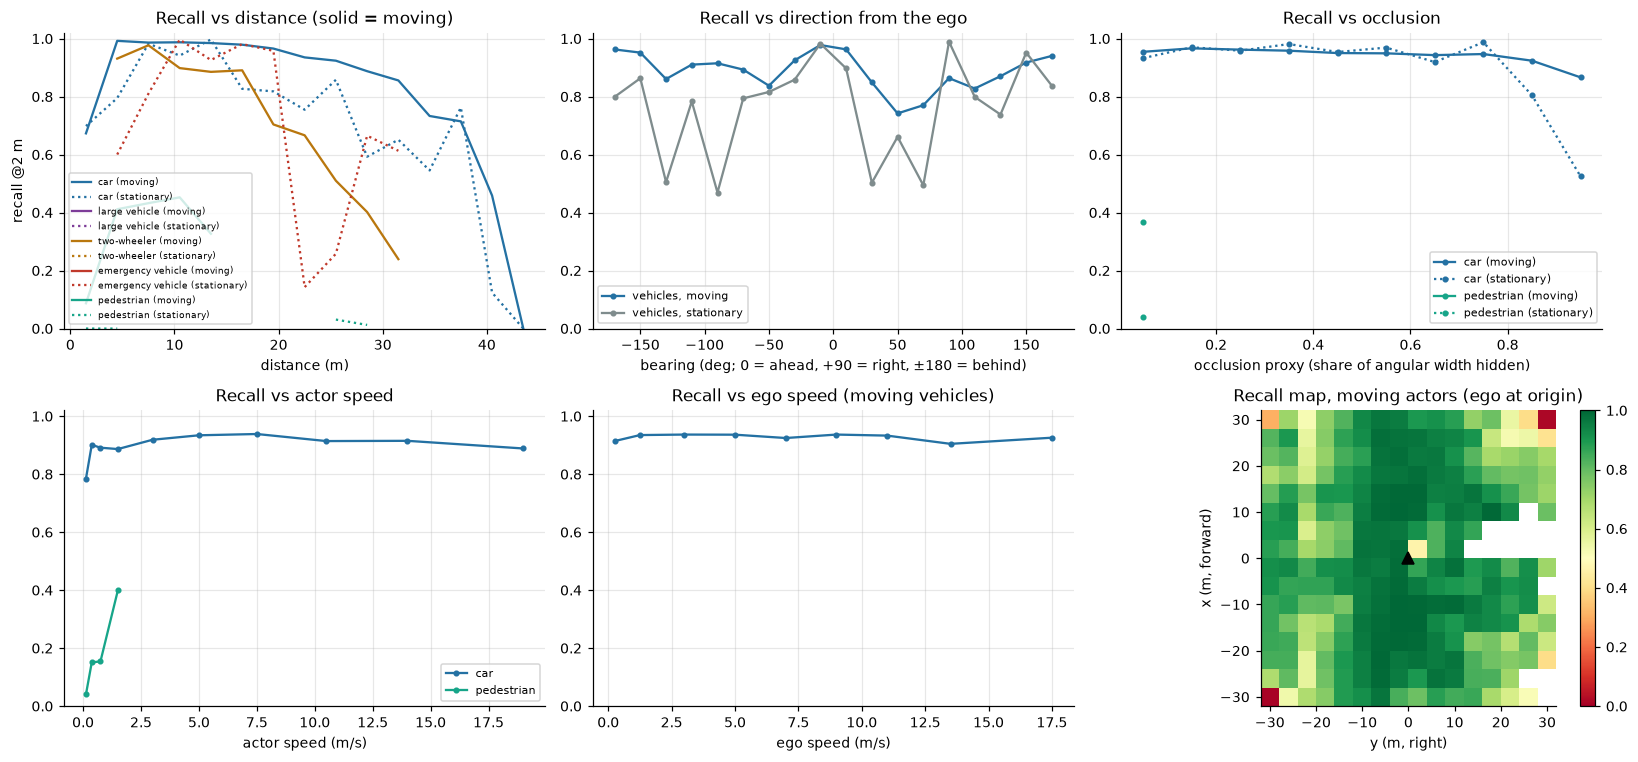

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
dbins = np.arange(0, 46, 3)
for c, name in enumerate(pa.GT_CATS):
    for mv, ls in ((True, "-"), (False, ":")):
        m = (gt["cat"] == c) & (gt["moving"] == mv)
        b = pa.binned(gt["dist"][m], gt[P][m].astype(float), dbins, min_n=200)
        axes[0, 0].plot(b[:, 0], b[:, 1], ls, color=CAT_COL[c], label=f"{name} ({'moving' if mv else 'stationary'})")
axes[0, 0].set_xlabel("distance (m)"); axes[0, 0].set_ylabel("recall @2 m"); axes[0, 0].set_ylim(0, 1.02)
axes[0, 0].legend(fontsize=6); axes[0, 0].set_title("Recall vs distance (solid = moving)")

for mv, c in ((True, "#2471a3"), (False, "#7f8c8d")):
    m = (gt["cat"] != 4) & (gt["moving"] == mv)
    b = pa.binned(gt["bearing"][m], gt[P][m].astype(float), np.arange(-180, 181, 20), min_n=200)
    axes[0, 1].plot(b[:, 0], b[:, 1], color=c, marker="o", ms=3, label="vehicles, " + ("moving" if mv else "stationary"))
axes[0, 1].set_xlabel("bearing (deg; 0 = ahead, +90 = right, ±180 = behind)"); axes[0, 1].set_ylim(0, 1.02)
axes[0, 1].legend(fontsize=7); axes[0, 1].set_title("Recall vs direction from the ego")

for c in (0, 4):
    for mv, ls in ((True, "-"), (False, ":")):
        m = (gt["cat"] == c) & (gt["moving"] == mv)
        b = pa.binned(gt["occ"][m], gt[P][m].astype(float), np.linspace(0, 1, 11), min_n=100)
        axes[0, 2].plot(b[:, 0], b[:, 1], ls, color=CAT_COL[c], marker="o", ms=3,
                        label=f"{pa.GT_CATS[c]} ({'moving' if mv else 'stationary'})")
axes[0, 2].set_xlabel("occlusion proxy (share of angular width hidden)"); axes[0, 2].set_ylim(0, 1.02)
axes[0, 2].legend(fontsize=7); axes[0, 2].set_title("Recall vs occlusion")

for c in (0, 4):
    m = gt["cat"] == c
    b = pa.binned(gt["speed"][m], gt[P][m].astype(float), np.r_[0, 0.25, 0.5, 1, 2, 4, 6, 9, 12, 16, 22], min_n=100)
    axes[1, 0].plot(b[:, 0], b[:, 1], color=CAT_COL[c], marker="o", ms=3, label=pa.GT_CATS[c])
axes[1, 0].set_xlabel("actor speed (m/s)"); axes[1, 0].set_ylim(0, 1.02); axes[1, 0].legend(fontsize=7)
axes[1, 0].set_title("Recall vs actor speed")

m = gt["moving"] & (gt["cat"] != 4)
b = pa.binned(gt["ego_speed"][m], gt[P][m].astype(float), np.r_[0, 0.5, 2, 4, 6, 8, 10, 12, 15, 20], min_n=200)
axes[1, 1].plot(b[:, 0], b[:, 1], color="#2471a3", marker="o", ms=3)
axes[1, 1].set_xlabel("ego speed (m/s)"); axes[1, 1].set_ylim(0, 1.02); axes[1, 1].set_title("Recall vs ego speed (moving vehicles)")

m = gt["moving"]
H, xe, ye = np.histogram2d(gt["x"][m], gt["y"][m], bins=[np.arange(-32, 33, 4), np.arange(-32, 33, 4)])
Hd, _, _ = np.histogram2d(gt["x"][m], gt["y"][m], bins=[xe, ye], weights=gt[P][m].astype(float))
R = np.where(H >= 100, Hd / np.maximum(H, 1), np.nan)
im = axes[1, 2].imshow(R, origin="lower", extent=[ye[0], ye[-1], xe[0], xe[-1]], vmin=0, vmax=1, cmap="RdYlGn", aspect="equal")
axes[1, 2].plot(0, 0, "k^", ms=8); axes[1, 2].set_xlabel("y (m, right)"); axes[1, 2].set_ylabel("x (m, forward)")
axes[1, 2].set_title("Recall map, moving actors (ego at origin)"); axes[1, 2].grid(False)
plt.colorbar(im, ax=axes[1, 2], fraction=0.046)
plt.tight_layout(); savefig("02_what_gets_missed"); plt.show()

In [9]:
rows = []
for name, m in (("moving vehicles, < 15 m, occlusion < 0.2", gt["moving"] & (gt["cat"] != 4) & (gt["dist"] < 15) & (gt["occ"] < 0.2)),
                ("moving vehicles, < 15 m, occlusion >= 0.5", gt["moving"] & (gt["cat"] != 4) & (gt["dist"] < 15) & (gt["occ"] >= 0.5)),
                ("moving vehicles, 25-32 m", gt["moving"] & (gt["cat"] != 4) & (gt["dist"] >= 25)),
                ("moving pedestrians, < 15 m, occlusion < 0.2", gt["moving"] & (gt["cat"] == 4) & (gt["dist"] < 15) & (gt["occ"] < 0.2)),
                ("moving pedestrians, < 15 m, occlusion >= 0.5", gt["moving"] & (gt["cat"] == 4) & (gt["dist"] < 15) & (gt["occ"] >= 0.5)),
                ("moving two-wheelers", gt["moving"] & (gt["cat"] == 2)),
                ("moving emergency vehicles", gt["moving"] & (gt["cat"] == 3)),
                ("stationary vehicles, < 15 m, occlusion < 0.2", ~gt["moving"] & (gt["cat"] != 4) & (gt["dist"] < 15) & (gt["occ"] < 0.2))):
    if m.sum() == 0:
        continue
    r = pa.ratio_ci(gt[P][m], np.ones(m.sum()), gt["route"][m])
    rows.append({"slice": name, "actor-steps": int(m.sum()), "routes": len(np.unique(gt["route"][m])), "recall @2 m [95% CI]": pci(r)})
show_table(rows)
write_csv("recall_slices", rows)

| slice | actor-steps | routes | recall @2 m [95% CI] |
|---|---|---|---|
| moving vehicles, < 15 m, occlusion < 0.2 | 132289 | 220 | 98.8% [98.0, 99.4] |
| moving vehicles, < 15 m, occlusion >= 0.5 | 18097 | 109 | 94.7% [89.1, 97.4] |
| moving vehicles, 25-32 m | 181706 | 220 | 84.5% [82.7, 86.1] |
| moving pedestrians, < 15 m, occlusion < 0.2 | 2877 | 20 | 38.5% [28.1, 57.7] |
| moving pedestrians, < 15 m, occlusion >= 0.5 | 73 | 9 | 69.9% [46.9, 90.5] |
| moving two-wheelers | 9180 | 20 | 82.1% [71.2, 90.1] |
| moving emergency vehicles | 1278 | 18 | 97.0% [93.9, 98.9] |
| stationary vehicles, < 15 m, occlusion < 0.2 | 231844 | 215 | 90.7% [84.8, 97.1] |

**Pedestrians, route by route.** Moving pedestrians appear in only 20 routes, so the pooled number hides large differences between scenarios. In `PedestrianCrossing`, three pedestrians cross together. The second table checks whether TF++ boxes **at least one** of the group (it could be merging them into a single box) and how many walker boxes it outputs per step.

In [10]:
mv = (gt["cat"] == 4) & gt["moving"]
rows = []
for r in np.unique(gt["route"][mv]):
    k = mv & (gt["route"] == r)
    rows.append({"route": int(r), "scenario": routes[str(r)]["scenario"], "moving pedestrians": len(np.unique(gt["id"][k])),
                 "actor-steps": int(k.sum()), "recall @2 m": float(gt[P][k].mean()), "recall @4 m": float(gt["det_4.0"][k].mean()),
                 "median distance (m)": float(np.median(gt["dist"][k]))})
rows.sort(key=lambda x: (x["scenario"], x["recall @2 m"]))
show_table(rows, fmt={"recall @2 m": pct, "recall @4 m": pct, "median distance (m)": lambda v: f"{v:.1f}"})
write_csv("pedestrian_routes", rows)

grp = []
for r in [x["route"] for x in rows if x["scenario"] == "PedestrianCrossing"]:
    k = mv & (gt["route"] == r)
    steps = np.unique(gt["step"][k])
    any_det = np.array([gt[P][k & (gt["step"] == s)].any() for s in steps])
    n_in = np.array([(k & (gt["step"] == s)).sum() for s in steps])
    b = box["route"] == r
    wb = collections.Counter(box["step"][b & (box["cls"] == 1)])
    grp.append({"route": int(r), "steps with >= 2 moving pedestrians in range": int((n_in >= 2).sum()),
                "share of those steps with >= 1 pedestrian boxed": float(any_det[n_in >= 2].mean()) if (n_in >= 2).any() else np.nan,
                "mean walker boxes per such step": float(np.mean([wb.get(s, 0) for s in steps[n_in >= 2]])) if (n_in >= 2).any() else np.nan,
                "mean moving pedestrians per such step": float(n_in[n_in >= 2].mean()) if (n_in >= 2).any() else np.nan})
if grp:
    show_table(grp, fmt={"share of those steps with >= 1 pedestrian boxed": pct,
                         "mean walker boxes per such step": lambda v: f"{v:.2f}", "mean moving pedestrians per such step": lambda v: f"{v:.2f}"})

| route | scenario | moving pedestrians | actor-steps | recall @2 m | recall @4 m | median distance (m) |
|---|---|---|---|---|---|---|
| 24211 | DynamicObjectCrossing | 1 | 55 | 3.6% | 3.6% | 9.1 |
| 24224 | DynamicObjectCrossing | 1 | 78 | 15.4% | 15.4% | 14.7 |
| 24252 | DynamicObjectCrossing | 1 | 75 | 60.0% | 65.3% | 6.0 |
| 24333 | DynamicObjectCrossing | 1 | 69 | 81.2% | 81.2% | 5.2 |
| 17752 | DynamicObjectCrossing | 1 | 66 | 98.5% | 98.5% | 7.1 |
| 24206 | ParkingCrossingPedestrian | 1 | 47 | 61.7% | 61.7% | 10.3 |
| 24294 | ParkingCrossingPedestrian | 1 | 77 | 84.4% | 84.4% | 7.0 |
| 3255 | ParkingCrossingPedestrian | 1 | 67 | 85.1% | 85.1% | 7.4 |
| 18252 | ParkingCrossingPedestrian | 1 | 77 | 87.0% | 87.0% | 7.7 |
| 3248 | ParkingCrossingPedestrian | 1 | 77 | 97.4% | 97.4% | 7.4 |
| 27515 | PedestrianCrossing | 3 | 336 | 2.7% | 2.7% | 3.6 |
| 27529 | PedestrianCrossing | 3 | 481 | 21.8% | 21.8% | 6.2 |
| 25863 | PedestrianCrossing | 3 | 480 | 25.4% | 25.4% | 7.1 |
| 27582 | PedestrianCrossing | 3 | 438 | 29.5% | 29.5% | 5.1 |
| 14194 | PedestrianCrossing | 3 | 409 | 31.3% | 31.3% | 7.1 |
| 3737 | VehicleTurningRoutePedestrian | 1 | 93 | 0.0% | 0.0% | 11.6 |
| 3731 | VehicleTurningRoutePedestrian | 1 | 49 | 28.6% | 28.6% | 4.6 |
| 10857 | VehicleTurningRoutePedestrian | 1 | 101 | 86.1% | 88.1% | 8.1 |
| 11381 | VehicleTurningRoutePedestrian | 1 | 100 | 87.0% | 87.0% | 6.1 |
| 2164 | VehicleTurningRoutePedestrian | 1 | 95 | 98.9% | 98.9% | 6.3 |

| route | steps with >= 2 moving pedestrians in range | share of those steps with >= 1 pedestrian boxed | mean walker boxes per such step | mean moving pedestrians per such step |
|---|---|---|---|---|
| 27515 | 93 | 9.7% | 0.10 | 2.71 |
| 27529 | 157 | 66.9% | 0.67 | 2.90 |
| 25863 | 157 | 77.1% | 0.78 | 2.90 |
| 27582 | 145 | 84.8% | 0.88 | 2.86 |
| 14194 | 137 | 91.2% | 0.96 | 2.84 |

## 5. False positives

Unmatched boxes at 2 m: **51,394 of 1,144,735** (4.49%); median score of matched boxes 0.83. Types, in rule order: near a static prop (<= 2.5 m), duplicate of an already-matched actor, a compatible actor within 4 m (poor localisation), otherwise a ghost.

| false-positive type | boxes | share of FPs | per minute of driving | median score |
|---|---|---|---|---|
| static prop | 28992 | 56.4% | 197.3 | 0.66 |
| duplicate | 586 | 1.1% | 4.0 | 0.41 |
| poorly localised (2-4 m) | 5987 | 11.6% | 40.7 | 0.42 |
| ghost | 15829 | 30.8% | 107.7 | 0.48 |

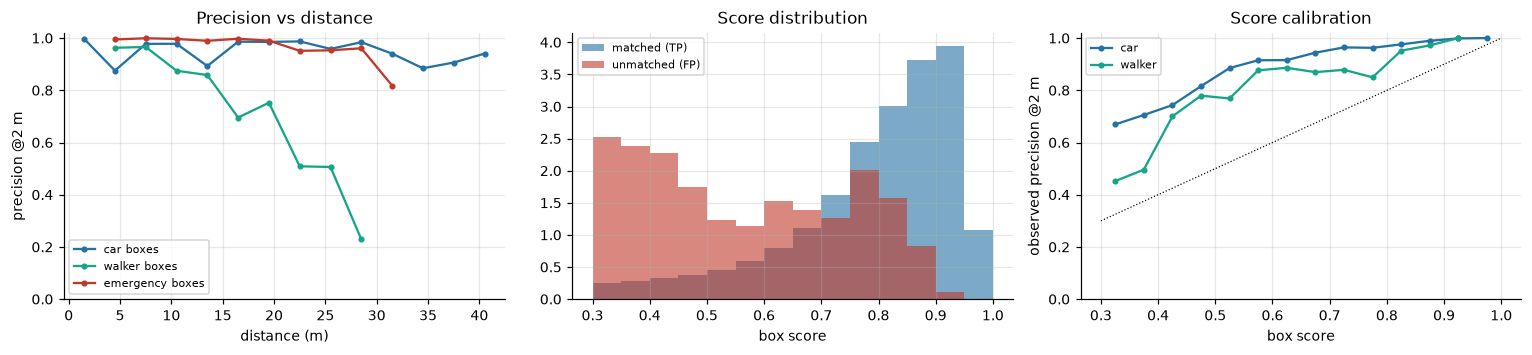

In [11]:
fp = ~box[PB]
types = collections.Counter(box["fp_type"][fp])
rows = []
for k in range(1, 5):
    rows.append({"false-positive type": pa.FP_TYPES[k], "boxes": types.get(k, 0), "share of FPs": types.get(k, 0) / max(fp.sum(), 1),
                 "per minute of driving": types.get(k, 0) / minutes,
                 "median score": float(np.median(box["score"][fp & (box["fp_type"] == k)])) if types.get(k, 0) else float("nan")})
display(Markdown(f"Unmatched boxes at 2 m: **{fp.sum():,} of {len(fp):,}** ({fp.mean():.2%}); "
                 f"median score of matched boxes {np.median(box['score'][~fp]):.2f}. Types, in rule order: near a static prop (<= 2.5 m), "
                 "duplicate of an already-matched actor, a compatible actor within 4 m (poor localisation), otherwise a ghost."))
show_table(rows, fmt={"share of FPs": pct, "per minute of driving": lambda v: f"{v:.1f}", "median score": lambda v: f"{v:.2f}"})
write_csv("false_positives", rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
for c, name, col in ((0, "car boxes", "#2471a3"), (1, "walker boxes", "#17a589"), (4, "emergency boxes", "#c0392b")):
    m = box["cls"] == c
    b = pa.binned(box["dist"][m], box[PB][m].astype(float), np.arange(0, 46, 3), min_n=50)
    axes[0].plot(b[:, 0], b[:, 1], marker="o", ms=3, color=col, label=name)
axes[0].set_ylim(0, 1.02); axes[0].set_xlabel("distance (m)"); axes[0].set_ylabel("precision @2 m"); axes[0].legend(fontsize=7)
axes[0].set_title("Precision vs distance")
bins = np.linspace(0.3, 1.0, 15)
axes[1].hist(box["score"][~fp], bins=bins, density=True, alpha=0.6, color="#2471a3", label="matched (TP)")
axes[1].hist(box["score"][fp], bins=bins, density=True, alpha=0.6, color="#c0392b", label="unmatched (FP)")
axes[1].set_xlabel("box score"); axes[1].legend(fontsize=7); axes[1].set_title("Score distribution")
for c, name, col in ((0, "car", "#2471a3"), (1, "walker", "#17a589")):
    m = box["cls"] == c
    b = pa.binned(box["score"][m], box[PB][m].astype(float), bins, min_n=30)
    axes[2].plot(b[:, 0], b[:, 1], marker="o", ms=3, color=col, label=name)
axes[2].plot([0.3, 1], [0.3, 1], "k:", lw=0.8); axes[2].set_xlabel("box score"); axes[2].set_ylabel("observed precision @2 m")
axes[2].set_ylim(0, 1.02); axes[2].legend(fontsize=7); axes[2].set_title("Score calibration")
plt.tight_layout(); savefig("03_false_positives"); plt.show()

## 6. Localisation and box attributes (matched pairs at 2 m)

| category | pairs | median centre error (m) | p90 centre error (m) | longitudinal bias (m) | lateral bias (m) | length error (m) | width error (m) | median BEV IoU | heading off >90 deg, moving | heading off >90 deg, stationary | median heading error (deg, excl. flips) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| car | 1007231 | 0.22 | 0.62 | -0.01 | 0.00 | 0.01 | 0.00 | 0.82 | 7.7% | 3.1% | 1.5 |
| two-wheeler | 16531 | 0.21 | 0.49 | 0.06 | 0.05 | 0.07 | -0.08 | 0.60 | 1.6% | 0.0% | 2.0 |
| emergency vehicle | 68130 | 0.21 | 0.73 | -0.05 | -0.04 | -0.21 | -0.04 | 0.83 | 0.1% | 0.0% | 1.7 |
| pedestrian | 1449 | 0.49 | 0.99 | -0.03 | -0.06 | -0.04 | -0.09 | 0.01 | 0.7% | 0.0% | 2.2 |

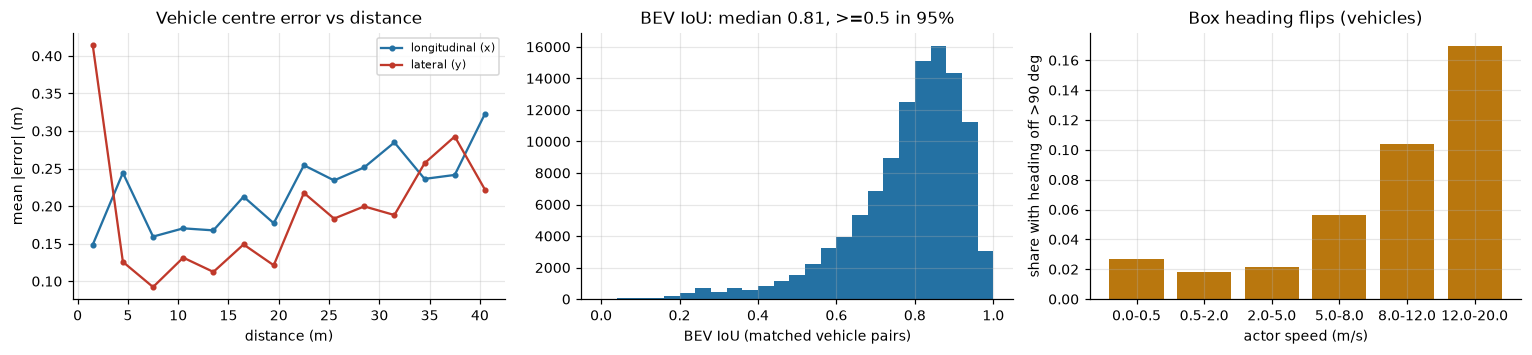

In [12]:
m = gt[P]
rows = []
for c, name in enumerate(pa.GT_CATS):
    k = m & (gt["cat"] == c)
    if k.sum() < 50:
        continue
    ex, ey = gt["err_x"][k], gt["err_y"][k]
    mv = k & gt["moving"]
    rows.append({"category": name, "pairs": int(k.sum()), "median centre error (m)": float(np.median(np.hypot(ex, ey))),
                 "p90 centre error (m)": float(np.percentile(np.hypot(ex, ey), 90)),
                 "longitudinal bias (m)": float(np.median(ex)), "lateral bias (m)": float(np.median(ey)),
                 "length error (m)": float(np.median(2 * gt["ext_err_x"][k])), "width error (m)": float(np.median(2 * gt["ext_err_y"][k])),
                 "median BEV IoU": float(np.nanmedian(gt["iou"][k])),
                 "heading off >90 deg, moving": float(np.mean(gt["head_err"][mv] > 90)) if mv.sum() else np.nan,
                 "heading off >90 deg, stationary": float(np.mean(gt["head_err"][k & ~gt["moving"]] > 90)) if (k & ~gt["moving"]).sum() else np.nan,
                 "median heading error (deg, excl. flips)": float(np.median(np.where(gt["head_err"][k] > 90, 180 - gt["head_err"][k], gt["head_err"][k])))})
show_table(rows, fmt={k: (lambda v: f"{v:.2f}") for k in rows[0] if "(m)" in k or "IoU" in k} |
           {"heading off >90 deg, moving": pct, "heading off >90 deg, stationary": pct, "median heading error (deg, excl. flips)": lambda v: f"{v:.1f}"})
write_csv("localisation", rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
k = m & (gt["cat"] != 4)
for comp, col, lab in (("err_x", "#2471a3", "longitudinal (x)"), ("err_y", "#c0392b", "lateral (y)")):
    b = pa.binned(gt["dist"][k], np.abs(gt[comp][k]), np.arange(0, 46, 3), min_n=100)
    axes[0].plot(b[:, 0], b[:, 1], marker="o", ms=3, color=col, label=lab)
axes[0].set_xlabel("distance (m)"); axes[0].set_ylabel("mean |error| (m)"); axes[0].legend(fontsize=7); axes[0].set_title("Vehicle centre error vs distance")
iou = gt["iou"][k & ~np.isnan(gt["iou"])]
axes[1].hist(iou, bins=np.linspace(0, 1, 26), color="#2471a3"); axes[1].set_xlabel("BEV IoU (matched vehicle pairs)")
axes[1].set_title(f"BEV IoU: median {np.median(iou):.2f}, >=0.5 in {np.mean(iou >= 0.5):.0%}")
spd = np.r_[0, 0.5, 2, 5, 8, 12, 20]
b = pa.binned(gt["speed"][k], (gt["head_err"][k] > 90).astype(float), spd, min_n=100)
axes[2].bar(range(len(b)), b[:, 1], color="#b9770e"); axes[2].set_xticks(range(len(b)), [f"{spd[i]}-{spd[i+1]}" for i in range(len(b))])
axes[2].set_xlabel("actor speed (m/s)"); axes[2].set_ylabel("share with heading off >90 deg"); axes[2].set_title("Box heading flips (vehicles)")
plt.tight_layout(); savefig("04_localisation"); plt.show()

## 7. Temporal stability of detections (per actor track)

| category | tracks (>= 1 s in range) | never detected | median track detection rate | dropouts per minute in range | entered range during route | median latency after entering range (s) | median distance at first detection (m) |
|---|---|---|---|---|---|---|---|
| car | 4422 | 1.5% | 98.8% | 14.44 | 3193 | 0.00 | 32.3 |
| two-wheeler | 34 | 2.9% | 76.3% | 18.02 | 32 | 0.30 | 30.3 |
| emergency vehicle | 81 | 1.2% | 96.7% | 24.29 | 65 | 0.00 | 31.7 |
| pedestrian | 30 | 10.0% | 25.0% | 20.59 | 0 | nan | nan |

/Users/hassaanmuzammil/.cache/uv/archive-v0/IrNLTKkogtZ0zU9IMoPv0/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


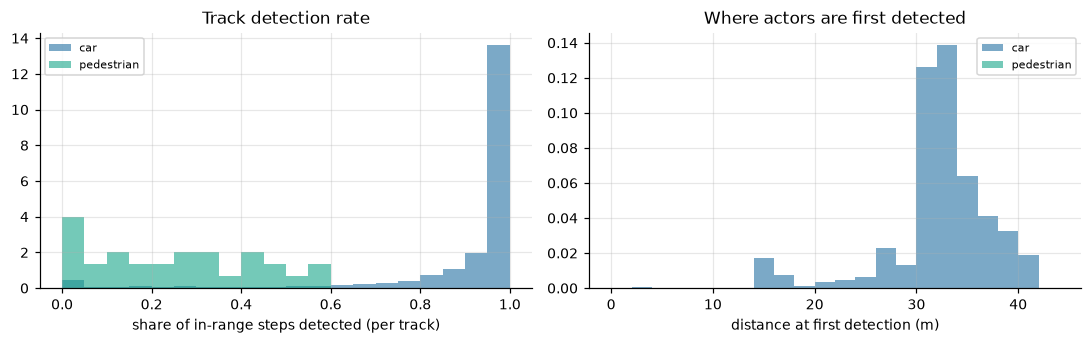

In [13]:
TR = pa.tracks(gt, P)
TRm = [t for t in TR if t["steps"] >= 20]
rows = []
for c, name in enumerate(pa.GT_CATS):
    ts = [t for t in TRm if t["cat"] == c]
    if not ts:
        continue
    secs = sum(t["steps"] for t in ts) * pa.DT
    ent = [t for t in ts if t["entered_in_range"] and not np.isnan(t["latency_s"])]
    rows.append({"category": name, "tracks (>= 1 s in range)": len(ts),
                 "never detected": float(np.mean([t["det_rate"] == 0 for t in ts])),
                 "median track detection rate": float(np.median([t["det_rate"] for t in ts])),
                 "dropouts per minute in range": sum(t["dropouts"] for t in ts) / (secs / 60),
                 "entered range during route": len(ent),
                 "median latency after entering range (s)": float(np.median([t["latency_s"] for t in ent])) if ent else np.nan,
                 "median distance at first detection (m)": float(np.median([t["first_det_dist"] for t in ent])) if ent else np.nan})
show_table(rows, fmt={"never detected": pct, "median track detection rate": pct, "dropouts per minute in range": lambda v: f"{v:.2f}",
                      "median latency after entering range (s)": lambda v: f"{v:.2f}", "median distance at first detection (m)": lambda v: f"{v:.1f}"})
write_csv("tracks", rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for c in (0, 4):
    ts = [t for t in TRm if t["cat"] == c]
    axes[0].hist([t["det_rate"] for t in ts], bins=np.linspace(0, 1, 21), alpha=0.6, color=CAT_COL[c], label=pa.GT_CATS[c], density=True)
    ent = [t for t in ts if t["entered_in_range"] and not np.isnan(t["first_det_dist"])]
    axes[1].hist([t["first_det_dist"] for t in ent], bins=np.arange(0, 46, 2), alpha=0.6, color=CAT_COL[c], label=pa.GT_CATS[c], density=True)
axes[0].set_xlabel("share of in-range steps detected (per track)"); axes[0].legend(fontsize=7); axes[0].set_title("Track detection rate")
axes[1].set_xlabel("distance at first detection (m)"); axes[1].legend(fontsize=7); axes[1].set_title("Where actors are first detected")
plt.tight_layout(); savefig("05_tracks"); plt.show()

## 8. Conditions: town, weather, scenario

In [14]:
rid = gt["route"].astype(str)
bid = box["route"].astype(str)
def slice_rows(key_fn, label):
    keys = sorted({key_fn(r) for r in routes if r in data})
    out = []
    for k in keys:
        rs = [int(r) for r in routes if r in data and key_fn(r) == k]
        g = np.isin(gt["route"], rs) & gt["moving"]
        b = np.isin(box["route"], rs)
        if g.sum() < 200:
            continue
        rc = pa.ratio_ci(gt[P][g], np.ones(g.sum()), gt["route"][g])
        pc = pa.ratio_ci(box[PB][b], np.ones(b.sum()), box["route"][b])
        out.append({label: k, "routes": len(rs), "recall, moving [95% CI]": pci(rc), "precision [95% CI]": pci(pc), "_r": rc[0]})
    return out

for fn, label in ((lambda r: routes[r]["town"], "town"),
                  (lambda r: ("night" if routes[r]["sun_altitude"] < 0 else "day") + (", rain" if routes[r]["precipitation"] > 20 else ", dry"), "weather"),
                  (lambda r: "fog >= 20" if routes[r]["fog"] >= 20 else "fog < 20", "fog"),
                  (lambda r: routes[r]["family"], "scenario family")):
    rows = slice_rows(fn, label)
    show_table(rows, [label, "routes", "recall, moving [95% CI]", "precision [95% CI]"])
    write_csv(f"by_{label.replace(' ', '_')}", rows)

| town | routes | recall, moving [95% CI] | precision [95% CI] |
|---|---|---|---|
| Town01 | 4 | 94.2% [89.9, 97.5] | 99.3% [98.9, 99.6] |
| Town02 | 4 | 92.3% [84.5, 97.2] | 98.6% [94.6, 99.8] |
| Town03 | 11 | 97.4% [92.7, 98.9] | 97.3% [95.4, 99.3] |
| Town04 | 12 | 89.5% [86.4, 92.4] | 98.9% [97.7, 99.1] |
| Town05 | 9 | 83.5% [74.3, 92.3] | 98.6% [98.0, 98.9] |
| Town06 | 6 | 95.0% [91.1, 96.9] | 99.1% [97.8, 99.2] |
| Town07 | 5 | 91.9% [82.4, 97.0] | 98.3% [95.3, 99.5] |
| Town10HD | 4 | 97.6% [97.0, 98.3] | 98.8% [98.4, 99.2] |
| Town11 | 7 | 89.4% [80.3, 96.4] | 98.9% [98.5, 99.3] |
| Town12 | 104 | 91.5% [90.0, 92.8] | 92.8% [85.8, 97.9] |
| Town13 | 47 | 93.0% [90.1, 95.3] | 99.2% [98.7, 99.4] |
| Town15 | 7 | 92.9% [91.2, 96.1] | 90.8% [81.4, 99.3] |

| weather | routes | recall, moving [95% CI] | precision [95% CI] |
|---|---|---|---|
| day, dry | 100 | 91.7% [90.1, 93.3] | 94.3% [87.5, 98.5] |
| day, rain | 67 | 93.3% [90.5, 95.3] | 96.8% [95.0, 98.2] |
| night, dry | 13 | 93.1% [89.9, 96.3] | 96.9% [93.9, 98.7] |
| night, rain | 40 | 92.0% [88.5, 94.9] | 97.9% [94.4, 99.4] |

| fog | routes | recall, moving [95% CI] | precision [95% CI] |
|---|---|---|---|
| fog < 20 | 151 | 91.7% [90.1, 93.1] | 94.6% [89.0, 98.4] |
| fog >= 20 | 69 | 93.6% [91.5, 94.9] | 97.0% [94.9, 98.7] |

| scenario family | routes | recall, moving [95% CI] | precision [95% CI] |
|---|---|---|---|
| cut_in_hazard | 30 | 93.7% [88.5, 95.9] | 99.2% [99.1, 99.4] |
| junction | 75 | 90.0% [88.3, 91.7] | 97.0% [95.6, 98.5] |
| lane_merge | 40 | 93.9% [91.4, 96.0] | 98.2% [97.4, 99.1] |
| obstacle_detour | 50 | 92.5% [90.9, 95.6] | 90.2% [79.7, 98.4] |
| vru_crossing | 25 | 87.3% [81.9, 92.0] | 97.1% [93.4, 98.9] |

In [15]:
rows = slice_rows(lambda r: routes[r]["scenario"], "scenario type")
rows.sort(key=lambda r: r["_r"])
display(Markdown("**By scenario type** (sorted by recall on moving actors; 5 routes each)."))
show_table(rows, ["scenario type", "routes", "recall, moving [95% CI]", "precision [95% CI]"])
write_csv("by_scenario_type", rows)

**By scenario type** (sorted by recall on moving actors; 5 routes each).

| scenario type | routes | recall, moving [95% CI] | precision [95% CI] |
|---|---|---|---|
| PedestrianCrossing | 5 | 74.7% [67.2, 81.1] | 97.9% [93.5, 99.0] |
| VehicleTurningRoutePedestrian | 5 | 81.6% [70.2, 94.2] | 99.4% [98.8, 99.5] |
| SignalizedJunctionLeftTurnEnterFlow | 5 | 84.4% [74.8, 90.9] | 99.0% [98.6, 99.4] |
| SignalizedJunctionLeftTurn | 5 | 86.0% [84.1, 88.0] | 95.9% [93.5, 99.6] |
| ParkedObstacle | 5 | 86.8% [76.1, 98.1] | 99.0% [98.7, 99.3] |
| VehicleTurningRoute | 5 | 87.4% [81.9, 93.1] | 98.0% [97.5, 98.5] |
| HighwayCutIn | 5 | 87.5% [80.6, 98.0] | 99.0% [98.3, 99.3] |
| NonSignalizedJunctionLeftTurn | 5 | 87.9% [83.2, 93.4] | 96.2% [90.4, 99.1] |
| NonSignalizedJunctionLeftTurnEnterFlow | 5 | 88.1% [82.5, 95.0] | 97.3% [93.9, 99.0] |
| MergerIntoSlowTrafficV2 | 5 | 88.5% [86.5, 90.0] | 98.0% [97.4, 98.5] |
| EnterActorFlow | 5 | 88.8% [85.4, 92.7] | 98.8% [98.4, 99.3] |
| VanillaNonSignalizedTurn | 5 | 89.3% [86.4, 91.9] | 96.0% [94.8, 97.3] |
| HazardAtSideLane | 5 | 90.1% [89.8, 92.8] | 99.1% [98.9, 99.5] |
| VanillaSignalizedTurnEncounterGreenLight | 5 | 90.6% [86.9, 94.6] | 99.3% [99.0, 99.5] |
| CrossingBicycleFlow | 5 | 90.7% [88.6, 92.7] | 97.7% [97.3, 98.0] |
| SequentialLaneChange | 5 | 90.8% [87.7, 95.7] | 99.4% [99.1, 99.6] |
| VanillaSignalizedTurnEncounterRedLight | 5 | 91.3% [84.3, 94.0] | 99.3% [98.3, 99.6] |
| VanillaNonSignalizedTurnEncounterStopsign | 5 | 91.5% [90.1, 92.6] | 95.9% [94.8, 96.7] |
| HardBreakRoute | 5 | 92.5% [87.8, 98.8] | 99.6% [99.4, 99.7] |
| OppositeVehicleRunningRedLight | 5 | 92.6% [87.6, 97.7] | 95.9% [89.5, 99.2] |
| MergerIntoSlowTraffic | 5 | 92.9% [89.3, 96.0] | 99.1% [98.8, 99.5] |
| InterurbanAdvancedActorFlow | 5 | 93.0% [78.9, 97.9] | 97.8% [96.1, 98.6] |
| BlockedIntersection | 5 | 93.0% [90.5, 96.1] | 97.3% [91.7, 99.5] |
| NonSignalizedJunctionRightTurn | 5 | 93.1% [91.3, 94.6] | 97.8% [97.0, 98.4] |
| SignalizedJunctionRightTurn | 5 | 93.3% [88.3, 96.6] | 97.8% [96.5, 99.2] |
| OppositeVehicleTakingPriority | 5 | 93.5% [91.5, 94.8] | 96.1% [94.4, 97.6] |
| StaticCutIn | 5 | 93.5% [72.9, 98.9] | 99.2% [98.8, 99.3] |
| HighwayExit | 5 | 93.7% [90.4, 97.4] | 97.9% [97.7, 99.5] |
| InvadingTurn | 5 | 94.1% [84.9, 97.6] | 99.4% [98.3, 99.7] |
| ConstructionObstacle | 5 | 94.2% [90.0, 98.4] | 98.6% [98.3, 99.0] |
| HazardAtSideLaneTwoWays | 5 | 94.8% [90.2, 97.9] | 99.4% [98.9, 99.7] |
| VehicleOpensDoorTwoWays | 5 | 95.1% [91.7, 99.3] | 99.4% [99.0, 99.6] |
| YieldToEmergencyVehicle | 5 | 95.3% [92.6, 97.7] | 99.6% [99.4, 99.7] |
| DynamicObjectCrossing | 5 | 95.5% [91.1, 98.1] | 84.6% [71.1, 98.4] |
| T_Junction | 5 | 95.6% [93.0, 96.9] | 97.6% [95.5, 99.1] |
| InterurbanActorFlow | 5 | 96.0% [95.2, 99.0] | 99.5% [97.2, 99.7] |
| AccidentTwoWays | 5 | 96.2% [95.2, 97.2] | 79.0% [67.1, 97.4] |
| ControlLoss | 5 | 96.8% [92.5, 99.9] | 99.4% [99.2, 99.6] |
| Accident | 5 | 97.6% [96.1, 98.7] | 99.1% [98.7, 99.5] |
| ParkedObstacleTwoWays | 5 | 97.8% [96.1, 99.4] | 99.6% [98.9, 99.7] |
| ParkingCrossingPedestrian | 5 | 97.9% [95.3, 98.8] | 99.0% [97.7, 99.5] |
| ConstructionObstacleTwoWays | 5 | 97.9% [94.3, 99.5] | 77.1% [71.2, 93.5] |
| ParkingExit | 5 | 99.0% [95.3, 99.8] | 97.3% [96.0, 99.3] |
| ParkingCutIn | 5 | 99.1% [98.4, 99.6] | 98.5% [96.8, 99.3] |

## 9. Perception and driving outcome

Two questions:

1. Do routes that failed have worse perception than routes that succeeded?
2. For each actor TF++ actually collided with (recorded by the leaderboard), was there a box on it 3, 2 and 1 s before first contact?

In [16]:
per_route = []
for r, d in data.items():
    if r not in outcomes:
        continue
    g = d["gt"]; b = d["box"]
    if len(g.get("step", [])) == 0:
        continue
    mv = g["speed"] >= 0.5
    per_route.append({"route": r, "failed": outcomes[r]["failed"], "recall_moving": float(g[P][mv].mean()) if mv.sum() >= 20 else np.nan,
                      "precision": float(b[PB].mean()) if len(b.get("step", [])) else np.nan})
rows = []
for f in (False, True):
    rr = [x for x in per_route if x["failed"] == f]
    rows.append({"routes": "failed" if f else "succeeded", "n": len(rr),
                 "median per-route recall (moving)": float(np.nanmedian([x["recall_moving"] for x in rr])),
                 "median per-route precision": float(np.nanmedian([x["precision"] for x in rr]))})
show_table(rows, fmt={"median per-route recall (moving)": pct, "median per-route precision": pct})

ev = []
for r, d in data.items():
    if r not in outcomes:
        continue
    g = d["gt"]
    for aid, (s, typ) in d["contacts"].items():
        if aid not in outcomes[r]["collided_ids"]:
            continue
        sel = g["id"] == aid
        rec = {"route": r, "scenario": routes[r]["scenario"], "actor": typ}
        for sec in (3, 2, 1):
            w = sel & (np.abs(g["step"] - (s - sec * pa.HZ)) <= 2)
            rec[f"{sec} s"] = ("detected" if g[P][w].any() else "missed") if w.any() else "out of range / not logged"
        ev.append(rec)
rows = []
for sec in ("3 s", "2 s", "1 s"):
    c = collections.Counter(e[sec] for e in ev)
    n_in = c["detected"] + c["missed"]
    rows.append({"before first contact": sec, "detected": c["detected"], "missed": c["missed"],
                 "out of range / not logged": c["out of range / not logged"], "detection rate in range": c["detected"] / n_in if n_in else np.nan})
display(Markdown(f"Collided actors (vehicles and pedestrians counted by the leaderboard): **{len(ev)}**"))
show_table(rows, fmt={"detection rate in range": pct})
write_csv("collided_actor_detection", ev)

| routes | n | median per-route recall (moving) | median per-route precision |
|---|---|---|---|
| succeeded | 158 | 93.4% | 98.8% |
| failed | 61 | 94.9% | 98.8% |

Collided actors (vehicles and pedestrians counted by the leaderboard): **55**

| before first contact | detected | missed | out of range / not logged | detection rate in range |
|---|---|---|---|---|
| 3 s | 26 | 3 | 26 | 89.7% |
| 2 s | 40 | 3 | 12 | 93.0% |
| 1 s | 54 | 1 | 0 | 98.2% |

## 10. Traffic lights and stop signs (not scored: no ground truth)

In [17]:
rows = []
for fam in sorted({routes[r]["family"] for r in data}):
    rs = [r for r in data if routes[r]["family"] == fam]
    n = sum(len(data[r]["steps"]["n_tl"]) for r in rs)
    rows.append({"family": fam, "steps": n,
                 "steps with a traffic-light box": sum(int((data[r]["steps"]["n_tl"] > 0).sum()) for r in rs) / n,
                 "steps with a stop-sign box": sum(int((data[r]["steps"]["n_stop"] > 0).sum()) for r in rs) / n})
show_table(rows, fmt={"steps with a traffic-light box": pct, "steps with a stop-sign box": pct})
sc = [r for r in data if "Stopsign" in routes[r]["scenario"]]
print("routes of type VanillaNonSignalizedTurnEncounterStopsign:", len(sc),
      "| share with at least one stop-sign box:", np.mean([data[r]["steps"]["n_stop"].max() > 0 for r in sc]))

| family | steps | steps with a traffic-light box | steps with a stop-sign box |
|---|---|---|---|
| cut_in_hazard | 18417 | 0.7% | 0.0% |
| junction | 53057 | 29.1% | 3.2% |
| lane_merge | 39078 | 6.1% | 0.4% |
| obstacle_detour | 54056 | 3.1% | 0.2% |
| vru_crossing | 11721 | 35.7% | 2.7% |

routes of type VanillaNonSignalizedTurnEncounterStopsign: 5 | share with at least one stop-sign box: 1.0


In [18]:
summary = {"routes": len(data), "steps": int(len(st["ego_speed"])), "gt_actor_steps": int(len(gt["step"])), "boxes": int(len(box["step"])),
           "recall_moving_2m": float(gt[P][gt["moving"]].mean()), "recall_all_2m": float(gt[P].mean()), "precision_2m": float(box[PB].mean())}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1)
print(json.dumps(summary, indent=1))

{
 "routes": 220,
 "steps": 176329,
 "gt_actor_steps": 1305262,
 "boxes": 1144735,
 "recall_moving_2m": 0.9226779687799813,
 "recall_all_2m": 0.837641025326716,
 "precision_2m": 0.9551040197076179
}


## 11. Findings

All numbers come from the outputs above: 220 routes, 176,329 steps (147 minutes of driving), 1.31 M ground-truth actor-steps in range and 1.14 M predicted car / walker / emergency boxes. Brackets are 95% route-bootstrap confidence intervals. The main match threshold is 2 m between box and actor centres.

### 11.1 What TF++'s perception outputs contain

| Output | Status |
|---|---|
| Boxes per step | About 6.5 boxes against 7.4 ground-truth actors in range |
| Classes in use | Almost all boxes are cars. Also 1,900 walker, 10,173 emergency, 27,731 traffic-light and 2,268 stop-sign boxes |
| **Box `speed` and `brake` fields** | **0 in every one of the 1.14 M boxes.** Only position, size, heading, class and score carry information. Any use of actor motion needs frame-to-frame tracking |
| Emergency class | Rarely used: emergency vehicles are boxed as *emergency* only 14.5% of the time and as *car* 85.5% |

### 11.2 Ground-truth caveat

Scenario actors parked below the map (50–500 m down, per the scenario-runner code) appear in the logged ground truth because it has no height. 1,891 stationary actor-steps (973 pedestrian, 918 car) sit **inside the ego's own footprint** without a collision, which is impossible above ground; more hidden actors sit at positions that cannot be identified. Stationary-actor and all-actor recall are therefore **lower bounds**. Moving-actor recall (40.7% of actor-steps) is the reliable headline.

### 11.3 Headline quality

| Metric | Value |
|---|---|
| Recall, moving actors | **92.3%** [91.1, 93.4] |
| Recall, all actors (lower bound) | 83.8% [79.7, 87.9] |
| Precision, all predicted boxes | **95.5%** [91.2, 98.1] |
| Recall / precision with a stricter 1 m match | 90.5% / 92.7% |
| Recall / precision with a stricter 0.5 m match | 79.9% / 80.2% |
| Average precision, vehicles (0.5 / 1 / 2 / 4 m) | 0.66 / 0.81 / 0.83 / 0.84; mean 0.78 |
| Average precision, pedestrians | mean 0.15 |

The AP values are lower bounds. They include hidden actors, and only boxes with score ≥ 0.3 are logged.

**Localisation of vehicles is very good:**

| Measure | Value |
|---|---|
| Median centre error | 0.22 m (90th percentile 0.62 m) |
| Systematic bias | none (longitudinal and lateral both ≈ 0.00 m) |
| Size error | ≈ 0 m |
| Median BEV IoU | 0.82 |
| Median heading error | 1.5° |
| Heading flipped by more than 90° | 7.7% of moving cars, 3.1% of stationary cars |

### 11.4 What gets missed

**Vehicles are detected almost perfectly close by:**

| Slice | Recall |
|---|---|
| Moving vehicles within 15 m, not occluded | **98.8%** [98.0, 99.4] |
| Moving vehicles within 15 m, mostly occluded | 94.7% [89.1, 97.4] |
| Moving vehicles at 25–32 m | 84.5% [82.7, 86.1] |
| Stationary vehicles within 15 m, not occluded | 90.7% [84.8, 97.1] (still affected by hidden actors) |

- Recall falls beyond about 20 m. It is lower toward the sides (bearing ±50–100°) than straight ahead or behind.
- Occlusion matters only when more than about 80% of the actor is hidden.
- Ego speed has no effect.

| Category (moving) | Recall | Notes |
|---|---|---|
| Car | 92.8% | |
| Emergency vehicle | 97.0% | Mostly labelled as car |
| Two-wheeler | 82.1% | Recall drops sharply past 15–20 m |
| **Pedestrian** | **38.2%** | 18.6% including stationary |

**Pedestrians are the real weakness, and it has two causes:**

1. **Groups are merged.** In `PedestrianCrossing`, about 2.9 pedestrians cross together. TF++ outputs at most about 1 walker box per step, so at least one of them is boxed in 67–91% of steps in 4 of 5 routes, but per-pedestrian recall is only 3–31%.
2. **Some single pedestrians are missed.** Examples: `DynamicObjectCrossing` 24211 (4%) and 24224 (15%), and `VehicleTurningRoutePedestrian` 3737 (0%) and 3731 (29%). Three of these four routes ended in a pedestrian collision. Other single-pedestrian routes reach 80–99%.

**Track stability:**

- For cars, 1.5% of tracks are never detected, and the median track is detected in 98.8% of its steps.
- Cars are boxed as soon as they enter range: median latency 0.0 s, median first-detection distance 32 m.
- Short dropouts are common: about 14 per minute of in-range time per car, almost all 1–2 steps long.
- For pedestrians, 10% of tracks are never detected, and the median track is detected in 25% of its steps.

### 11.5 False positives

4.5% of boxes match no actor within 2 m. False-positive boxes have lower scores than correct ones (median 0.42–0.66 against 0.83).

| False-positive type | Share of false positives | What it is |
|---|---|---|
| Static prop | 56% | Construction cones and similar props, boxed as cars. Arguably useful, since they are obstacles, but not a scored class |
| Ghost | 31% | Nothing nearby. Median score 0.48 |
| Poorly localised | 12% | The right actor, but the box centre is 2–4 m off |
| Duplicate | 1% | A second box on an already-matched actor |

The static-prop cases drive the lowest-precision scenarios: `ConstructionObstacleTwoWays` 77%, `AccidentTwoWays` 79% and `DynamicObjectCrossing` 85%.

### 11.6 Conditions

- **Weather has no measurable effect.** Recall on moving actors is 91.7–93.3% across day/night × dry/rain, and fog makes no difference either.
- **Towns:** the lowest recall is Town05 at 83.5% (9 routes); the others are 89–98%.
- **Scenario families:** VRU-crossing has the lowest recall (87.3%), and obstacle-detour the lowest precision (90.2%, because of the props).
- **Lowest-recall scenario types:** `PedestrianCrossing` 74.7%, `VehicleTurningRoutePedestrian` 81.6%, then the junction left-turn types at 84–88%.

### 11.7 Perception vs driving outcome

- **Failed routes do not have worse perception.** Median per-route recall on moving actors is 94.9% for failed routes against 93.4% for successful ones; median precision is 98.8% for both.
- **Collided actors were usually detected.** Of the 55 actors TF++ collided with (counted by the leaderboard), those within box range were detected **89.7% / 93.0% / 98.2%** of the time at 3 / 2 / 1 s before first contact. At 3 s, 26 of the 55 were still out of range or not yet logged.
- The exceptions are the pedestrian cases in 11.4.

### 11.8 Conclusions for the project

1. **For vehicles, perception is not the bottleneck.** TF++ finds and localises nearby moving vehicles with about 99% recall, about 0.2 m error and good precision. Collided vehicles were in its boxes 1–3 s ahead. Vehicle crashes are therefore planning failures, which supports monitoring at the planning level ("commit or recover").
2. **TF++'s box outputs need post-processing before a geometric monitor can use them:**
   - estimate speed by tracking boxes from frame to frame (the speed field is always 0);
   - fix heading flips using the motion direction;
   - smooth over 1–2-step dropouts;
   - treat boxed construction props as obstacles rather than false alarms.
3. **Pedestrians are a genuine perception failure.** Low recall, merged groups and complete misses in some crossing scenarios mean pedestrian crashes cannot be blamed on the planner alone. An output-level monitor will struggle there, so keep pedestrian scenarios out of the core scenario families or analyse them separately.
4. **Logging fixes for the next run:**
   - Log actor height (z), or a visible / hidden flag, so actors parked below the map can be removed from the ground truth. That would make the stationary-actor and AP numbers exact.
   - If perception of the road layout matters, also log TF++'s BEV-semantics output, which is not evaluated here because it is not logged.

### 11.9 Limitations

- **One run per route.** Steps within a route are strongly correlated, which is why all intervals resample routes.
- **Matching uses centre distance, not IoU.** BEV IoU is reported on every 10th step only.
- **Stationary and all-actor recall, and AP, are lower bounds**, because of the hidden-actor problem and because only boxes with score ≥ 0.3 are logged.
- **The occlusion estimate is 2D.** It ignores height, so a car can count as "hidden" behind a lower car that a LiDAR mounted high on the ego could see over. Pedestrians are not counted as occluders.
- **Traffic lights and stop signs are not scored.** There is no ground truth for them; stop-sign boxes do appear in all 5 stop-sign routes.

### 11.10 Output files

All under `results/bench2drive_v2/perception/`:

| File | Contents |
|---|---|
| `box_inventory.csv` | Box counts and scores per class |
| `headline_recall_precision.csv`, `average_precision.csv` | Headline metrics |
| `recall_by_category.csv`, `recall_slices.csv`, `pedestrian_routes.csv` | Recall breakdowns |
| `false_positives.csv` | False-positive types |
| `localisation.csv` | Position, size, heading errors and IoU |
| `tracks.csv` | Track stability |
| `by_town.csv`, `by_weather.csv`, `by_fog.csv`, `by_scenario_family.csv`, `by_scenario_type.csv` | Condition breakdowns |
| `collided_actor_detection.csv` | Detection of collided actors at 3 / 2 / 1 s |
| `summary.json` | Headline numbers |
| `figures/*.png` | The figures in this notebook |
